# Lab Task 6: Bit Plane Slicing and Histogram Processing

## Images used
| File | What it is | Used in |
|------|-----------|---------|
| `img/u_group.png` | Outdoor group photo | Tasks 1, 2, 3 (dark image) |
| `img/u_code.png` | Code screenshot, white background | Task 3 (bright image) |
| `img/u_proctor.png` | Webcam frame from my ProctorAI project | Task 4, and a low contrast version for Tasks 5 to 7 |

The images are not in the repo. Put them in an `img/` folder next to this notebook before running it.

## 0. Setup

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

IMG = Path("img")

def load(name):
    im = cv2.imread(str(IMG / name), cv2.IMREAD_GRAYSCALE)
    assert im is not None, f"missing {IMG / name}"
    return im

def show_with_hist(imgs, titles):
    fig, ax = plt.subplots(2, len(imgs), figsize=(5.5 * len(imgs), 7))
    for i, (im, t) in enumerate(zip(imgs, titles)):
        ax[0, i].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(t); ax[0, i].axis("off")
        ax[1, i].hist(im.ravel(), bins=256, range=(0, 256), color="black")
        ax[1, i].set_title("Histogram: " + t); ax[1, i].set_xlim(0, 255); ax[1, i].set_xlabel("Intensity")
    plt.tight_layout(); plt.show()

# Part A: Bit Plane Slicing
## Task 1: Bit Plane Extraction

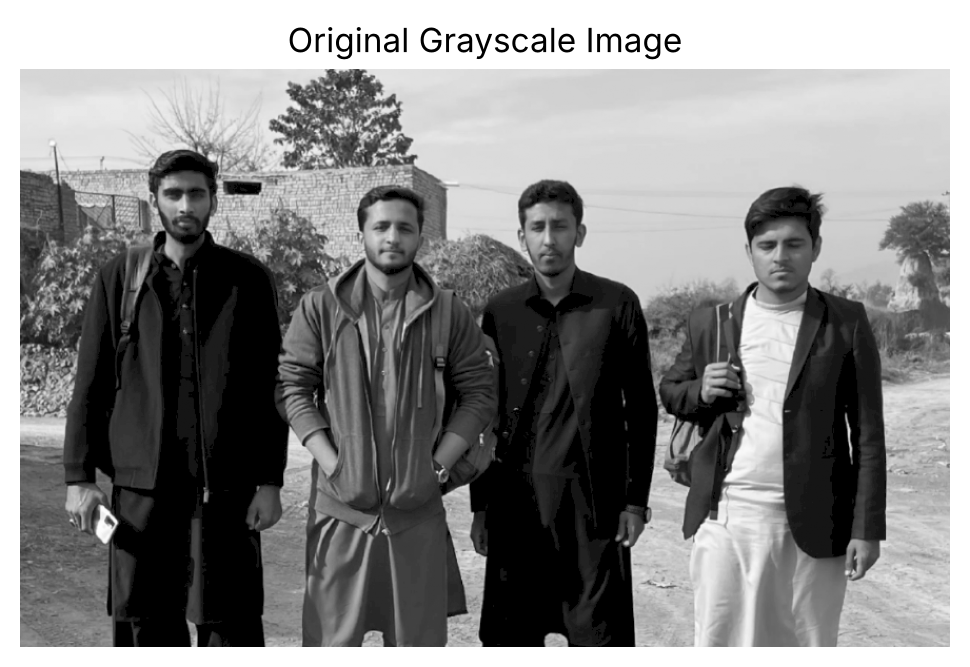

Bit plane 0: unique values = [0 1], ones = 41.0%
Bit plane 1: unique values = [0 1], ones = 41.2%
Bit plane 2: unique values = [0 1], ones = 46.1%
Bit plane 3: unique values = [0 1], ones = 38.9%
Bit plane 4: unique values = [0 1], ones = 48.0%
Bit plane 5: unique values = [0 1], ones = 34.8%
Bit plane 6: unique values = [0 1], ones = 49.2%
Bit plane 7: unique values = [0 1], ones = 43.1%


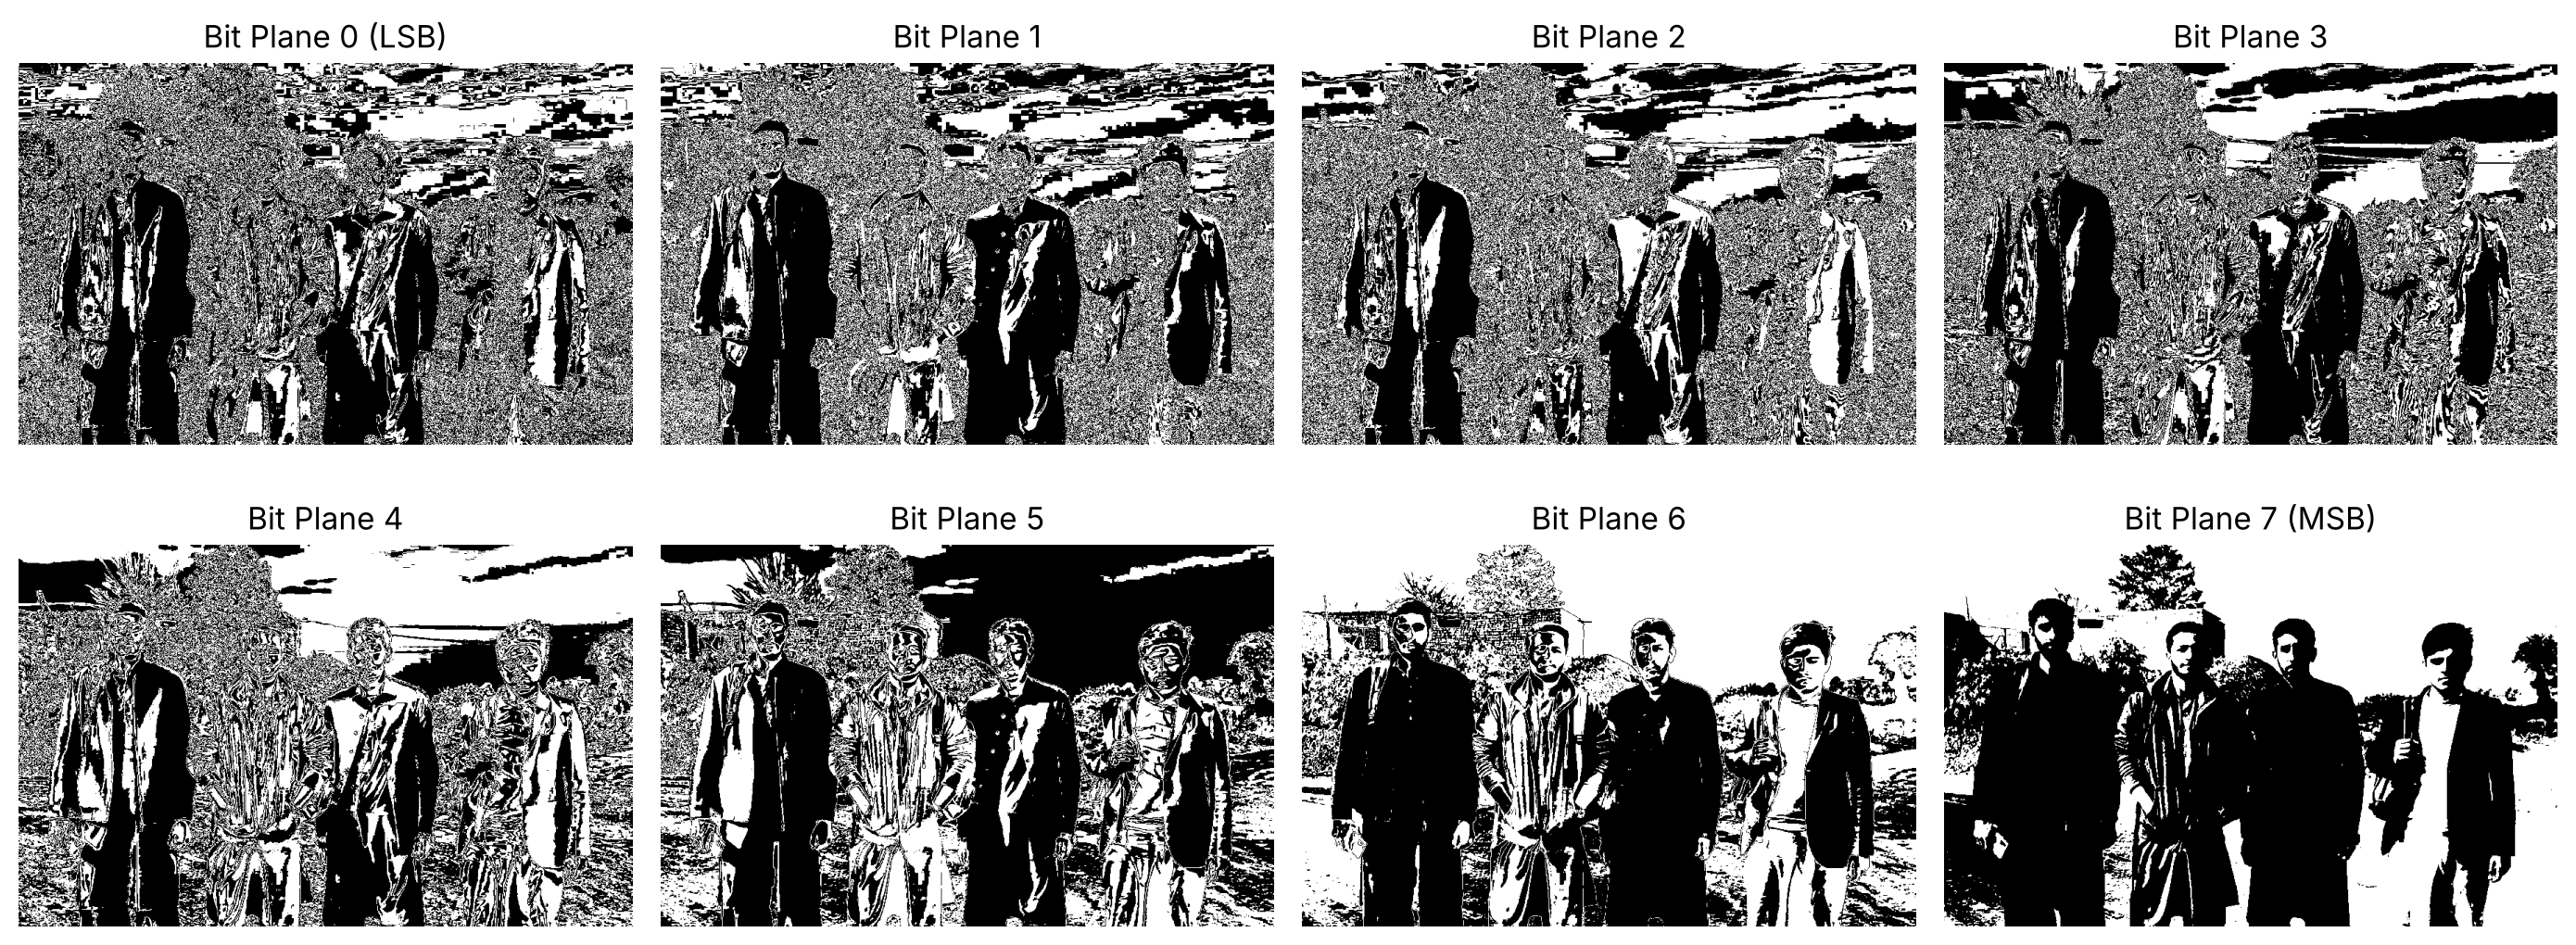

In [2]:
img = load("u_group.png")
plt.figure(figsize=(6, 4)); plt.imshow(img, cmap="gray"); plt.title("Original Grayscale Image"); plt.axis("off"); plt.show()

planes = [(img >> k) & 1 for k in range(8)]   # each plane holds only 0 and 1
for k, p in enumerate(planes):
    print(f"Bit plane {k}: unique values = {np.unique(p)}, ones = {p.mean()*100:.1f}%")

fig, ax = plt.subplots(2, 4, figsize=(14, 5.6))
for k in range(8):
    a = ax[k // 4, k % 4]
    a.imshow(planes[k], cmap="gray", vmin=0, vmax=1)
    a.set_title(f"Bit Plane {k}" + (" (LSB)" if k == 0 else " (MSB)" if k == 7 else ""))
    a.axis("off")
plt.tight_layout(); plt.show()

## Task 2: Comparative Analysis
- **Planes 7, 6, 5** keep the main structure. Plane 7 alone shows all four people, the wall and the tree clearly.
- **Planes 4, 3** still show the people, but the bushes and ground turn grainy and the sky breaks into bands.
- **Planes 2, 1, 0** are mostly noise. Solid black areas on the clothes appear only because those pixels are close to 0.
- High bits decide the big brightness jumps (bit 7 is worth 128 levels), low bits change a pixel by only 1 to 4 levels.
- **Most recognizable single plane: bit plane 7 (MSB).**

# Part B: Histogram Processing
## Task 3: Histogram Calculation and Interpretation

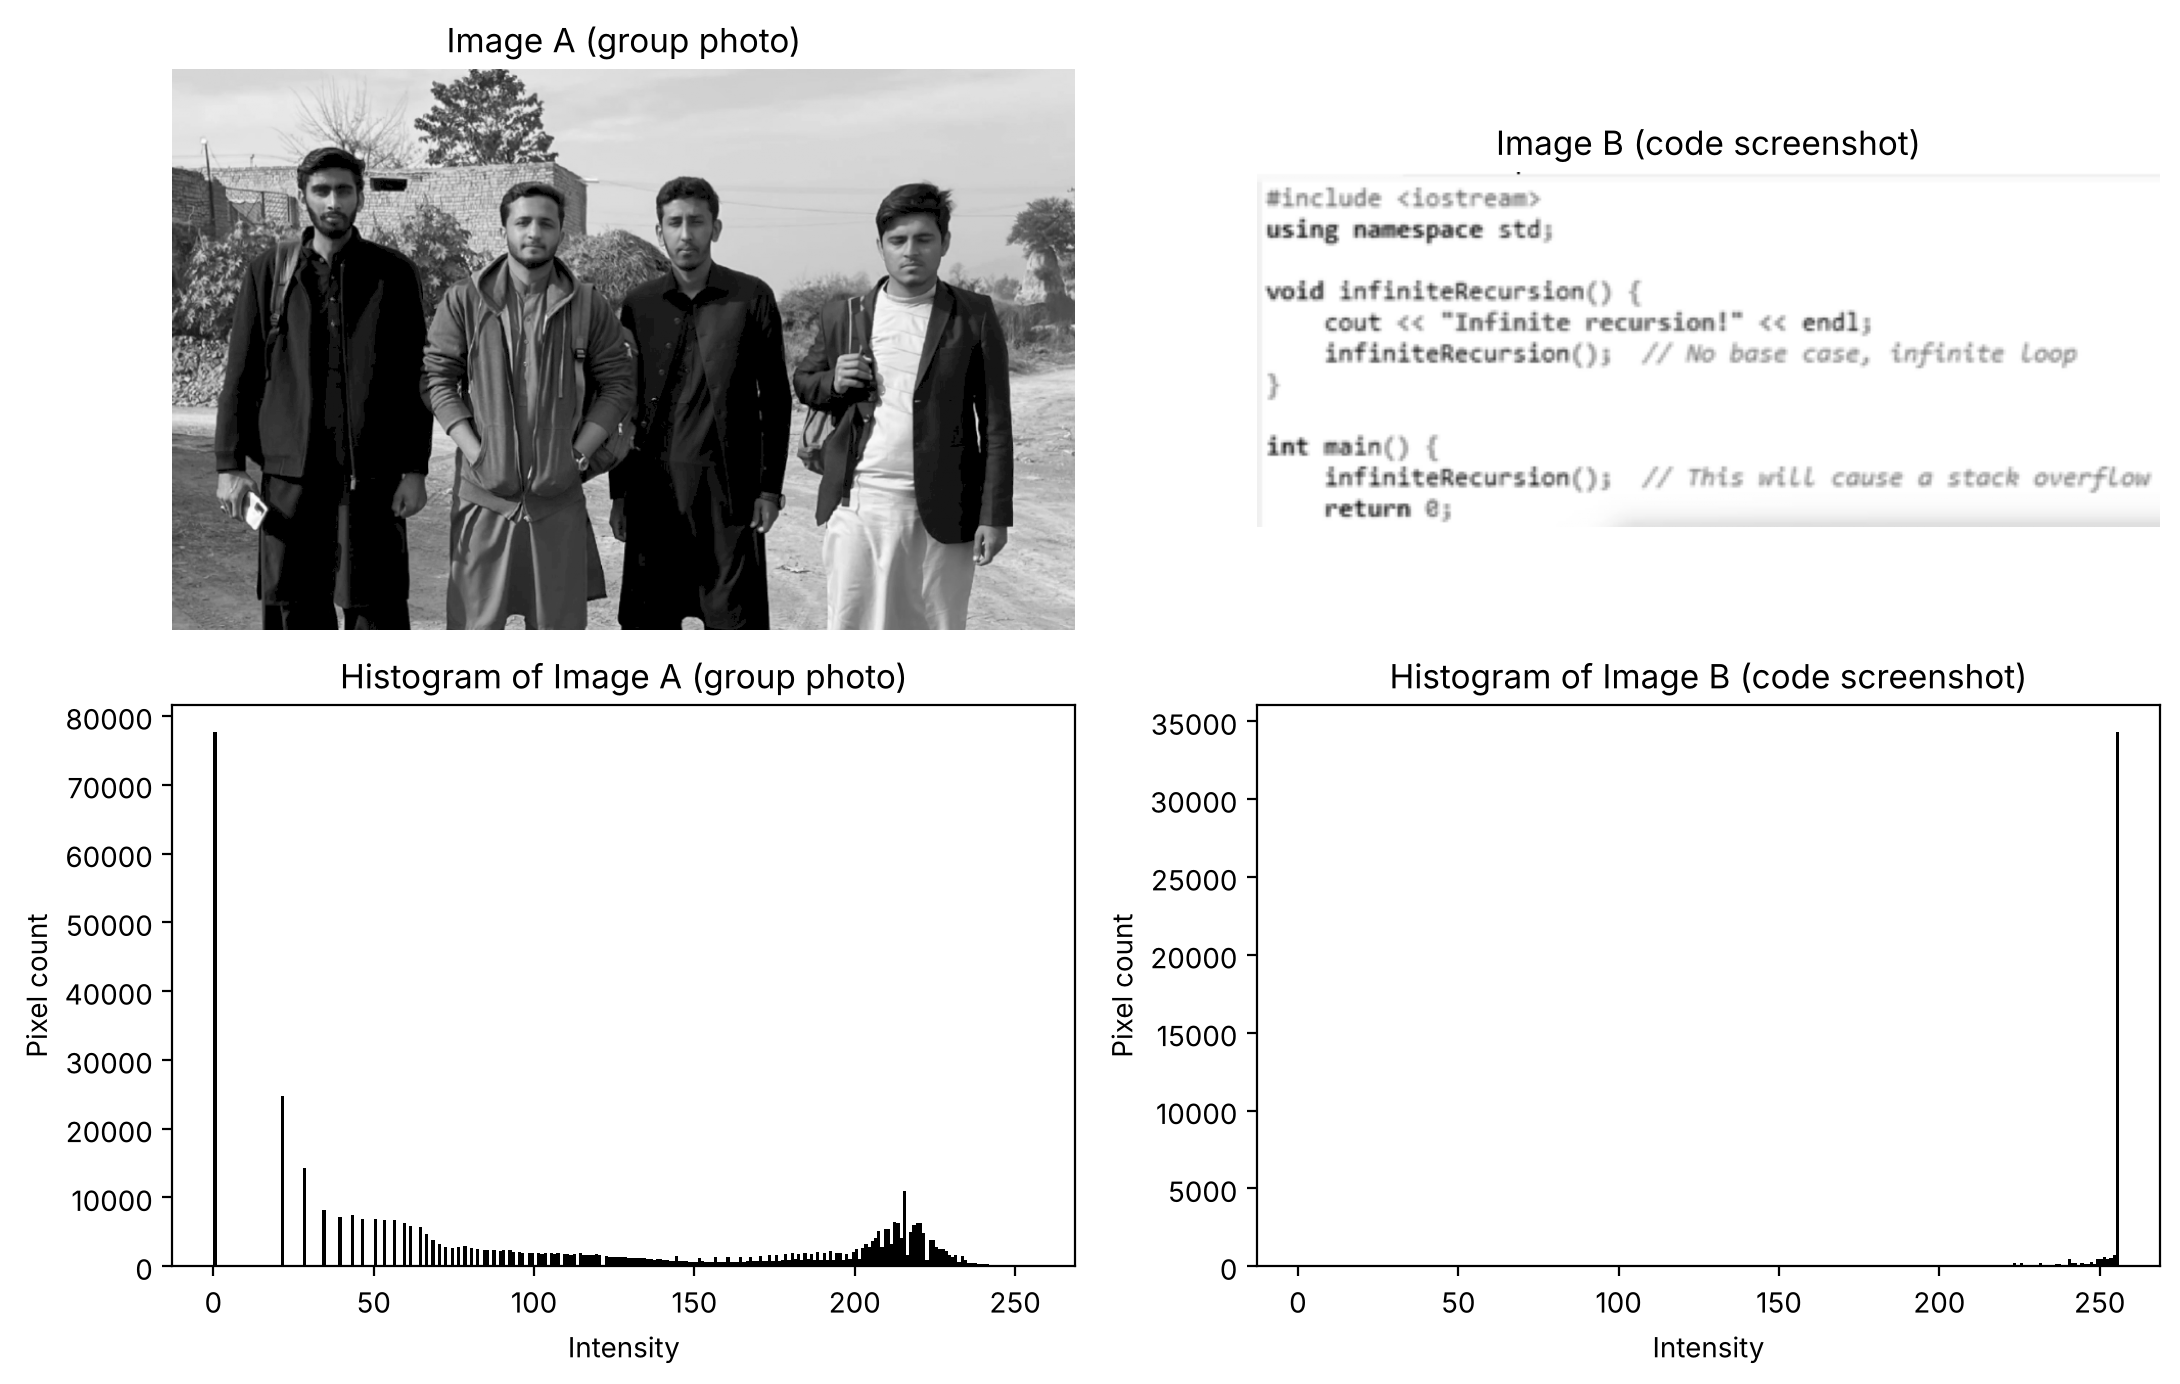

Image A mean = 111.76, median = 103
Image B mean = 244.62, median = 255


In [3]:
dark, bright = load("u_group.png"), load("u_code.png")
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for i, (im, t) in enumerate([(dark, "Image A (group photo)"), (bright, "Image B (code screenshot)")]):
    ax[0, i].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(t); ax[0, i].axis("off")
    ax[1, i].hist(im.ravel(), bins=256, range=(0, 256), color="black"); ax[1, i].set_title("Histogram of " + t)
    ax[1, i].set_xlabel("Intensity"); ax[1, i].set_ylabel("Pixel count")
plt.tight_layout(); plt.show()
print(f"Image A mean = {dark.mean():.2f}, median = {np.median(dark):.0f}")
print(f"Image B mean = {bright.mean():.2f}, median = {np.median(bright):.0f}")

Image A is darker (spike near 0 from the black clothes). Image B is brighter, almost all pixels sit at 255 (white background).
The x axis is intensity 0 to 255 and the y axis is how many pixels have that value. Bars on the left mean a dark image, on the right a bright one, and a narrow band means low contrast.

## Task 4: Normalized Histogram

Total pixels = 319908 | sum of histogram = 319908
Sum of normalized histogram = 1.000000


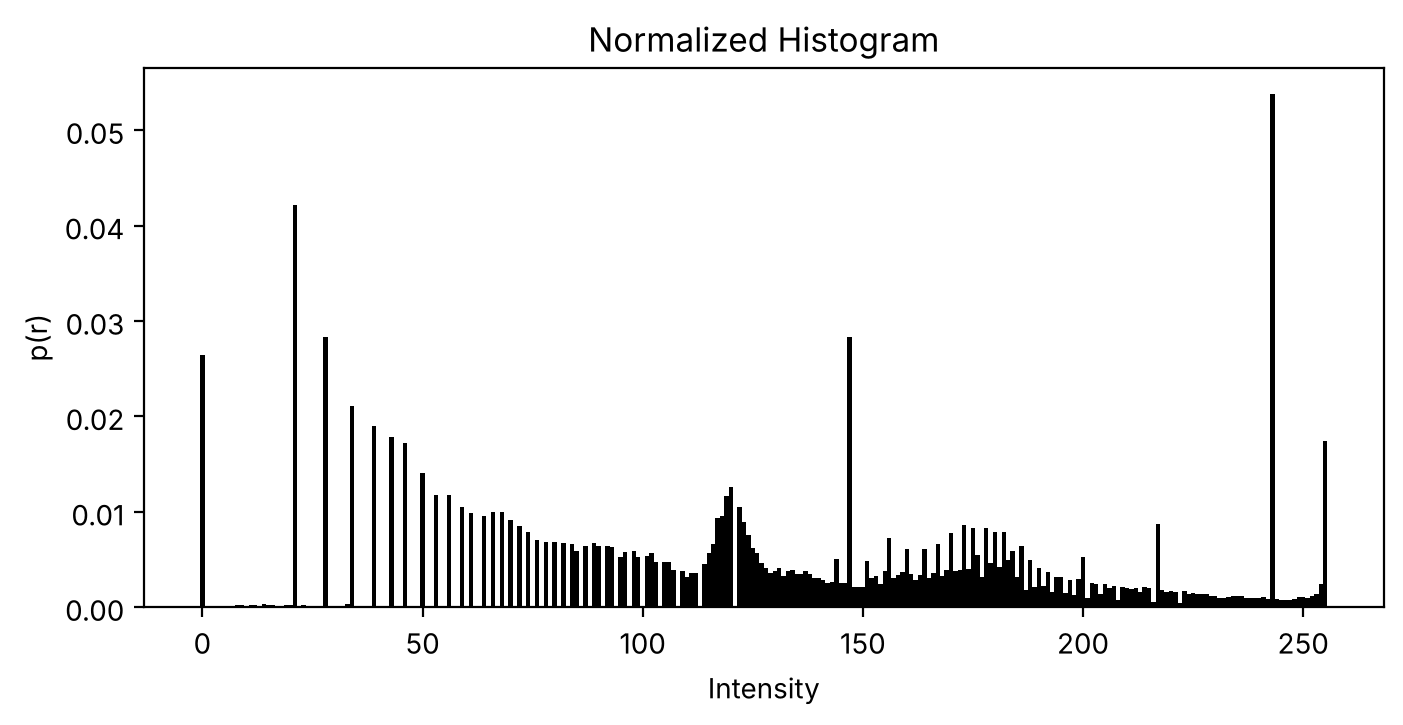

In [4]:
img4 = load("u_proctor.png")
hist = cv2.calcHist([img4], [0], None, [256], [0, 256]).ravel()
total = img4.shape[0] * img4.shape[1]
norm = hist / total
print("Total pixels =", total, "| sum of histogram =", int(hist.sum()))
print(f"Sum of normalized histogram = {norm.sum():.6f}")
plt.figure(figsize=(8, 3.5)); plt.bar(range(256), norm, width=1, color="black")
plt.title("Normalized Histogram"); plt.xlabel("Intensity"); plt.ylabel("p(r)"); plt.show()

## Task 5: Contrast Stretching
None of my images was really low contrast, so a hazy version of the webcam frame is made by squeezing its range.

Before: min=85, max=161, std=20.69, levels=77
After : min=0, max=255, std=69.43, levels=77


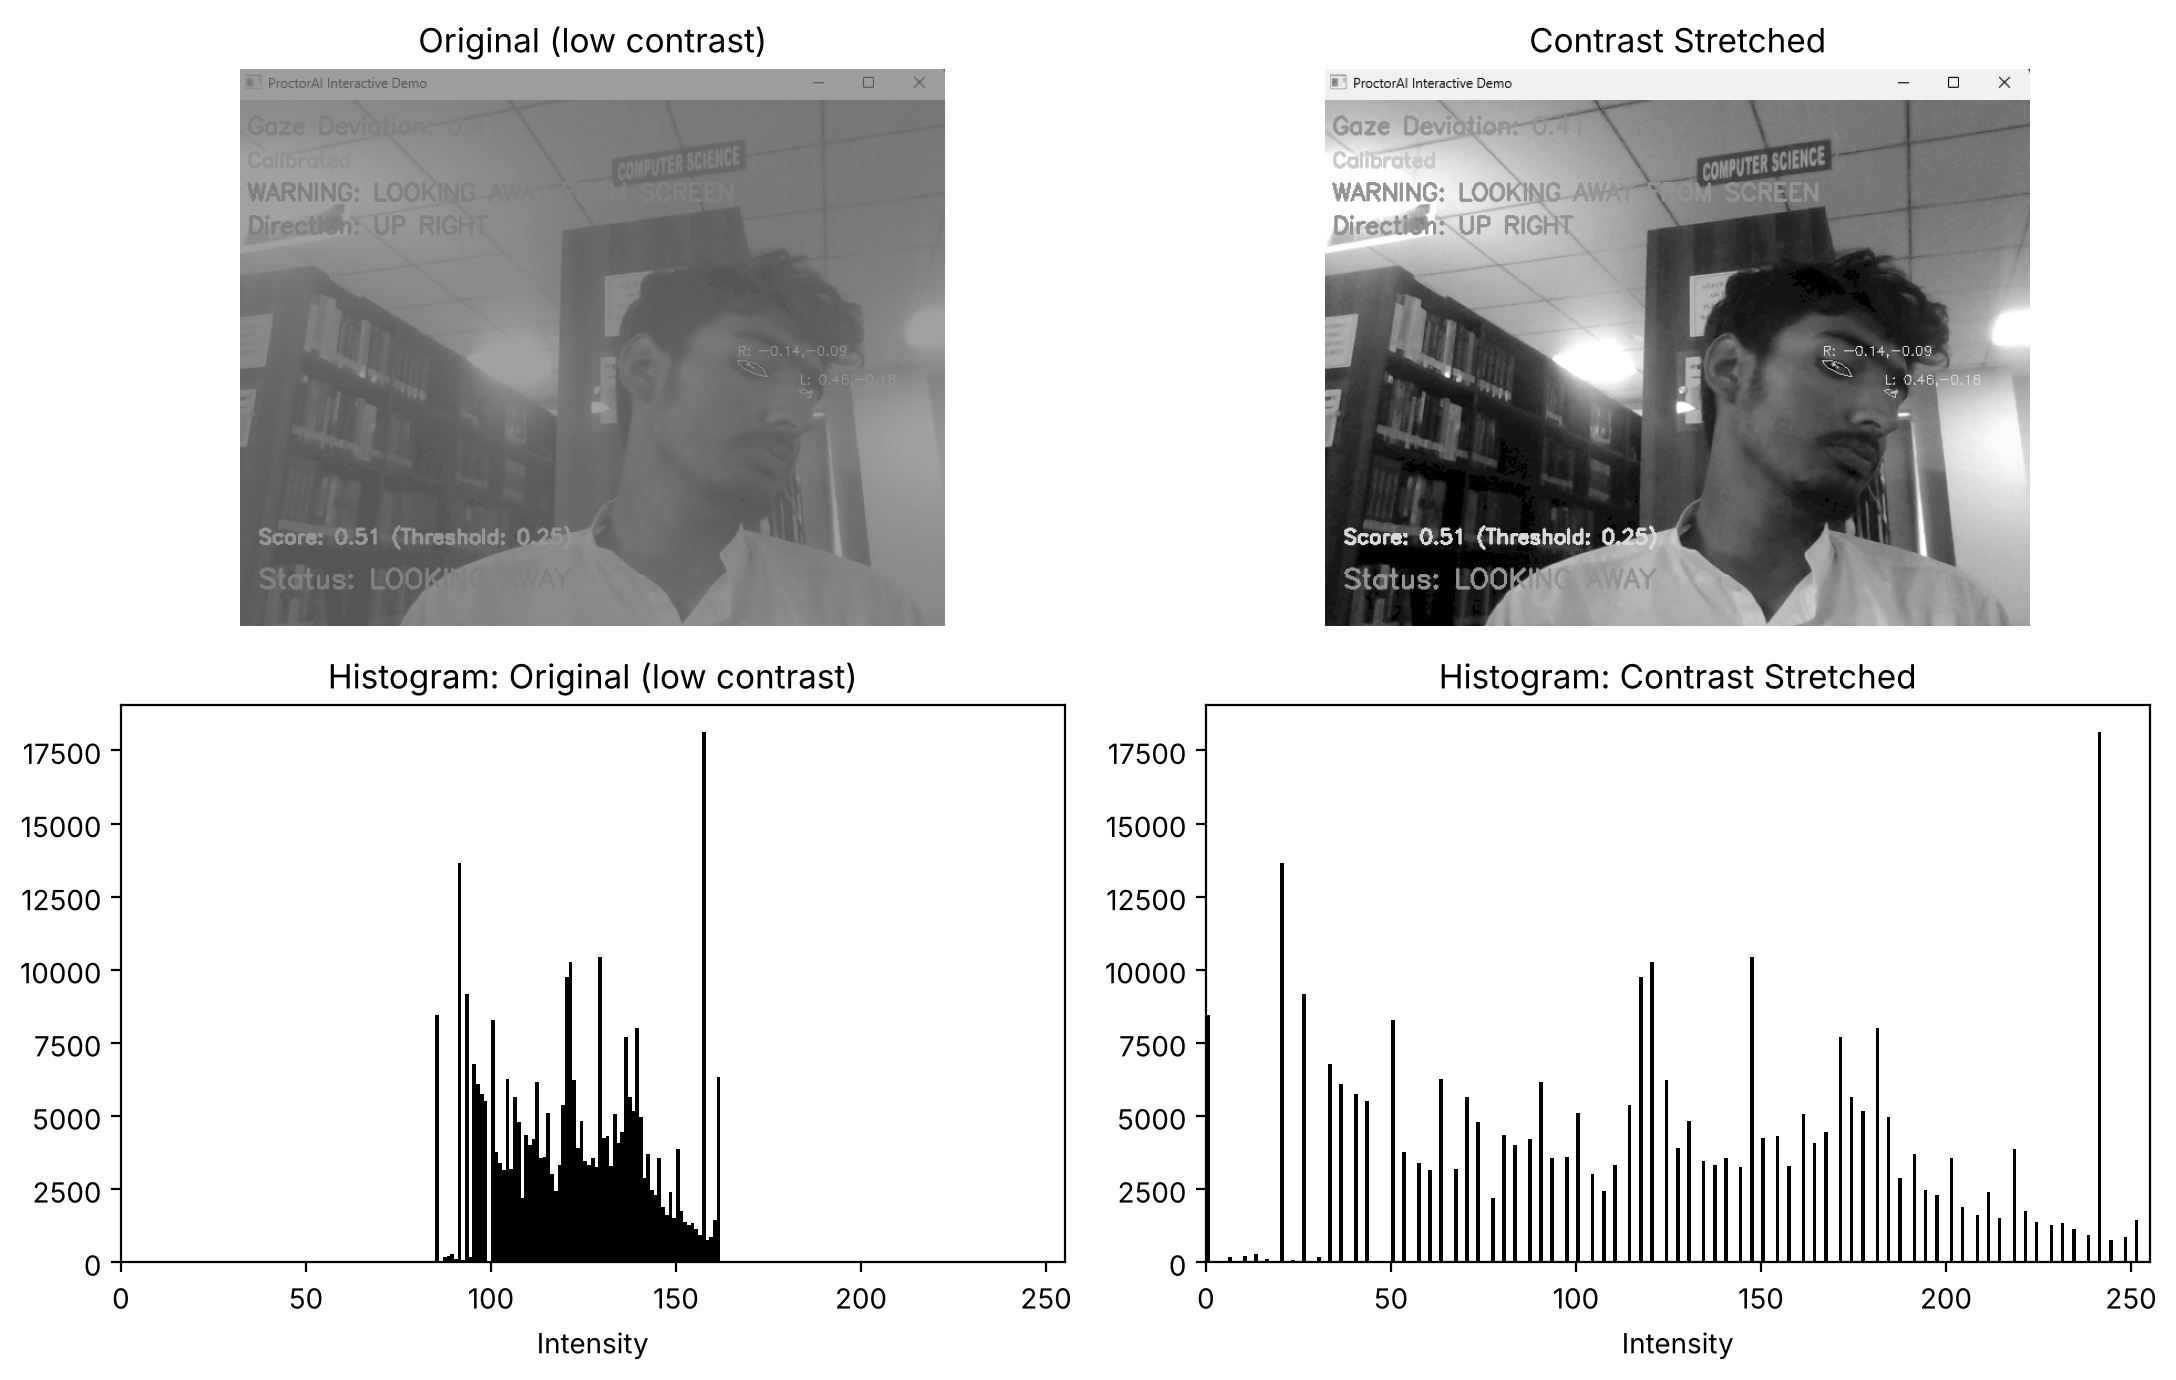

In [5]:
low = (img4.astype(np.float32) * 0.30 + 85).astype(np.uint8)
rmin, rmax = int(low.min()), int(low.max())
stretched = ((low.astype(np.float32) - rmin) / (rmax - rmin) * 255).astype(np.uint8)
print(f"Before: min={rmin}, max={rmax}, std={low.std():.2f}, levels={len(np.unique(low))}")
print(f"After : min={stretched.min()}, max={stretched.max()}, std={stretched.std():.2f}, levels={len(np.unique(stretched))}")
show_with_hist([low, stretched], ["Original (low contrast)", "Contrast Stretched"])

The histogram is pulled from 85 to 161 out to the full 0 to 255 range with the same shape.
Limitations: the number of gray levels stays the same (gaps appear), and one outlier pixel at 0 or 255 would stop the stretch from doing anything.

## Task 6: Histogram Equalization

Equalized: min=0, max=255, std=75.60, levels=70


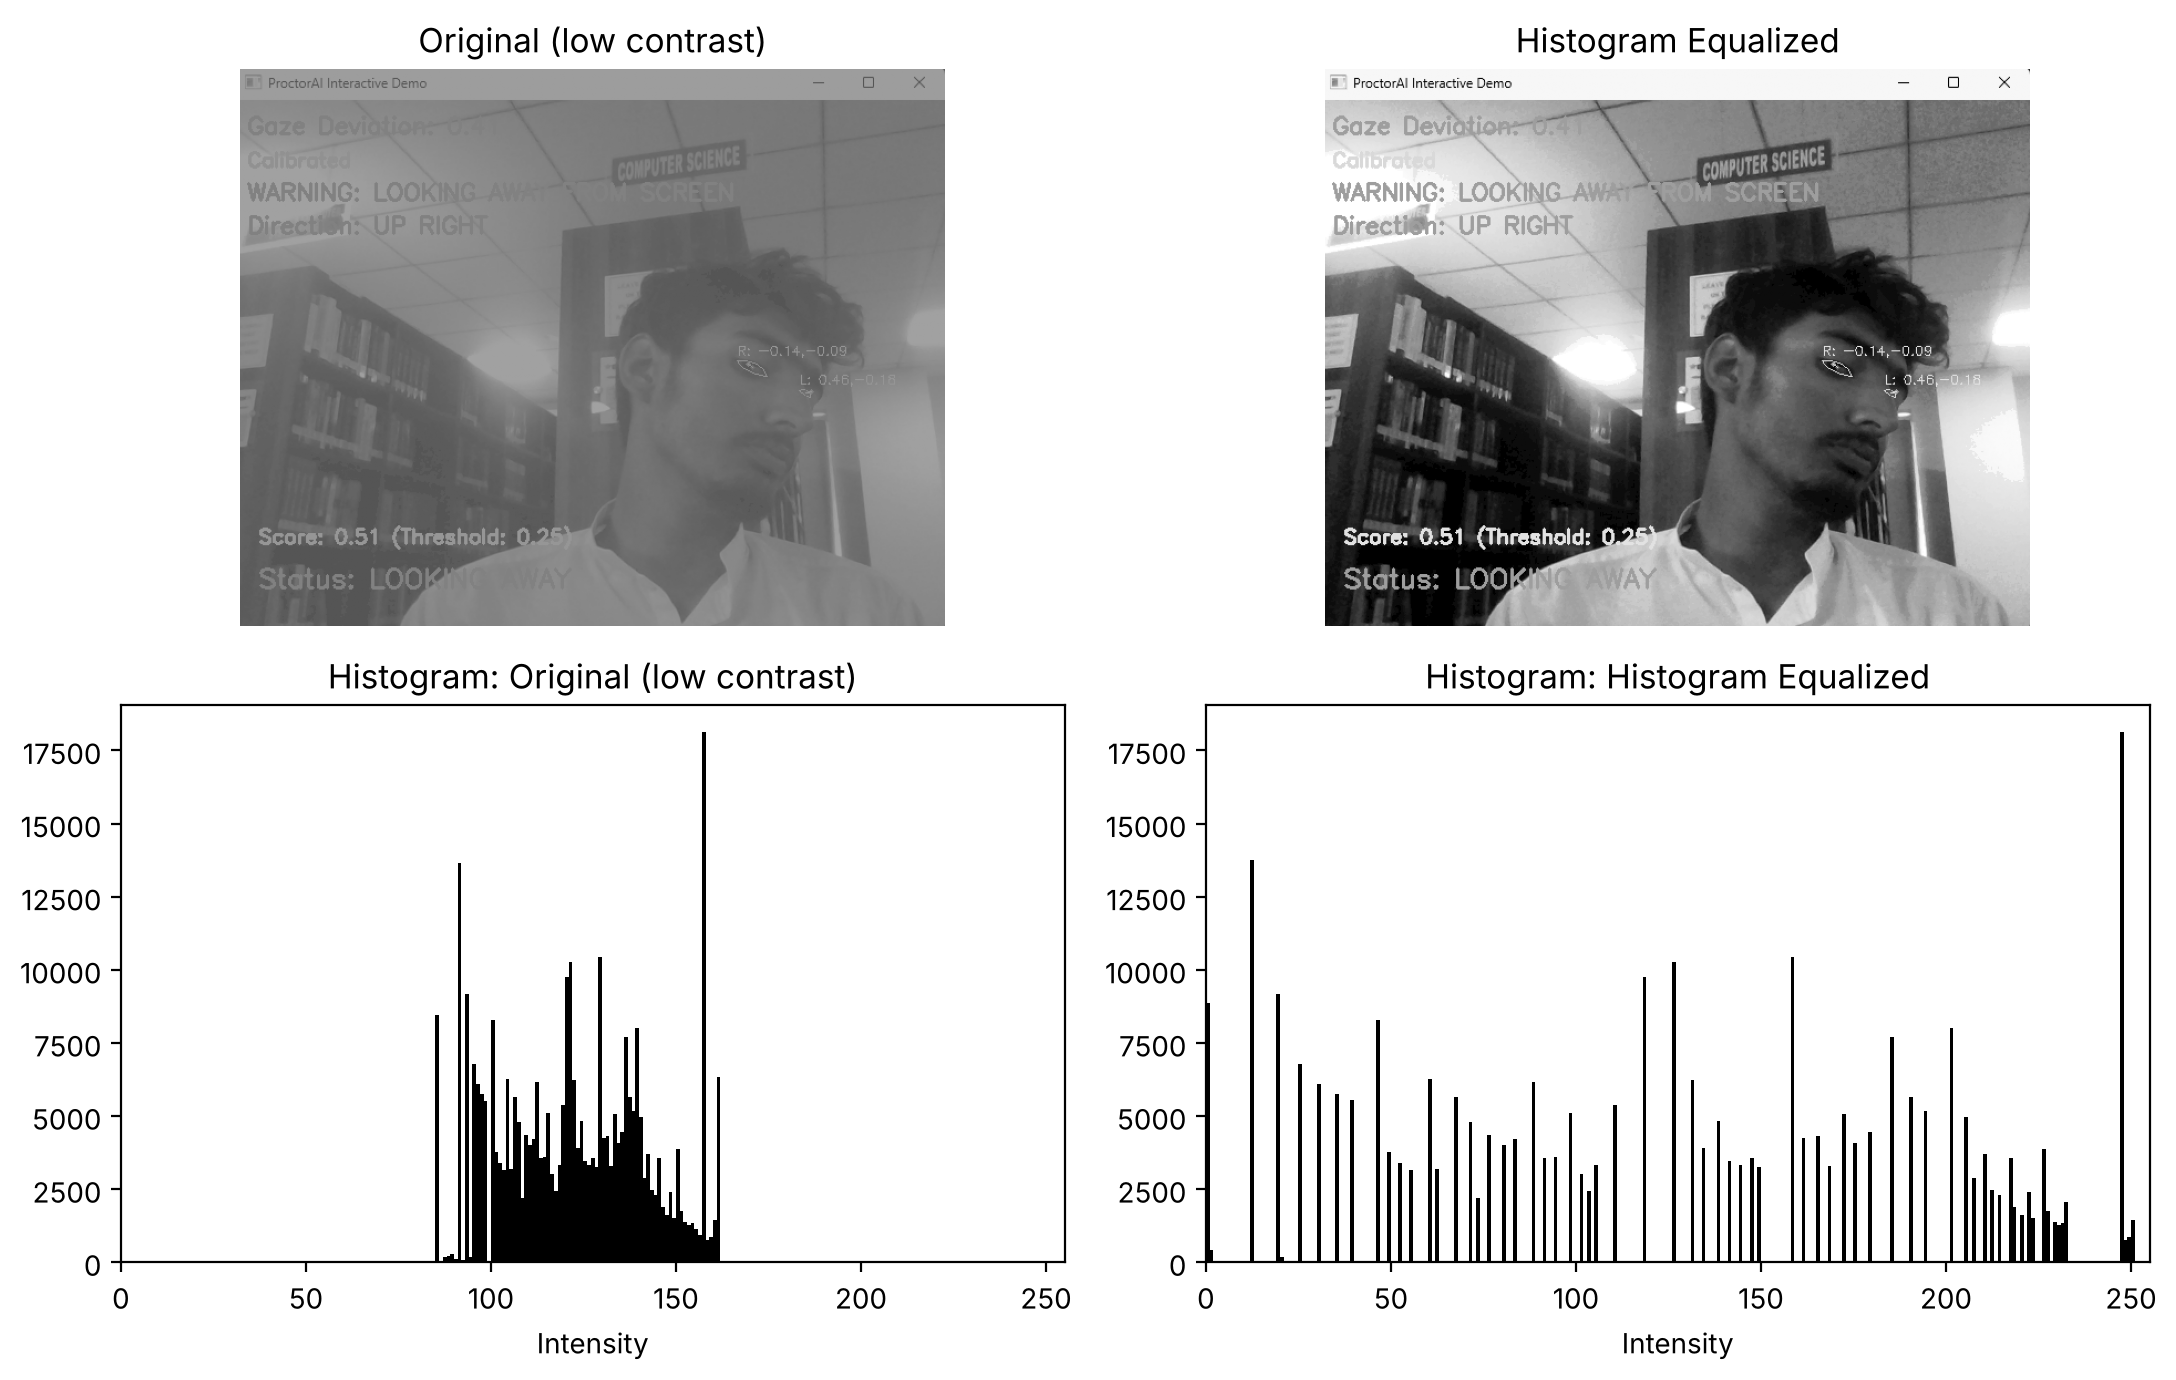

In [6]:
equalized = cv2.equalizeHist(low)
print(f"Equalized: min={equalized.min()}, max={equalized.max()}, std={equalized.std():.2f}, levels={len(np.unique(equalized))}")
show_with_hist([low, equalized], ["Original (low contrast)", "Histogram Equalized"])

Equalization maps each level with s = 255 x CDF(r), so crowded intensity ranges get spread over a wider output range. The bookshelves, the sign and the face become much clearer.

## Task 7: Comparative Analysis

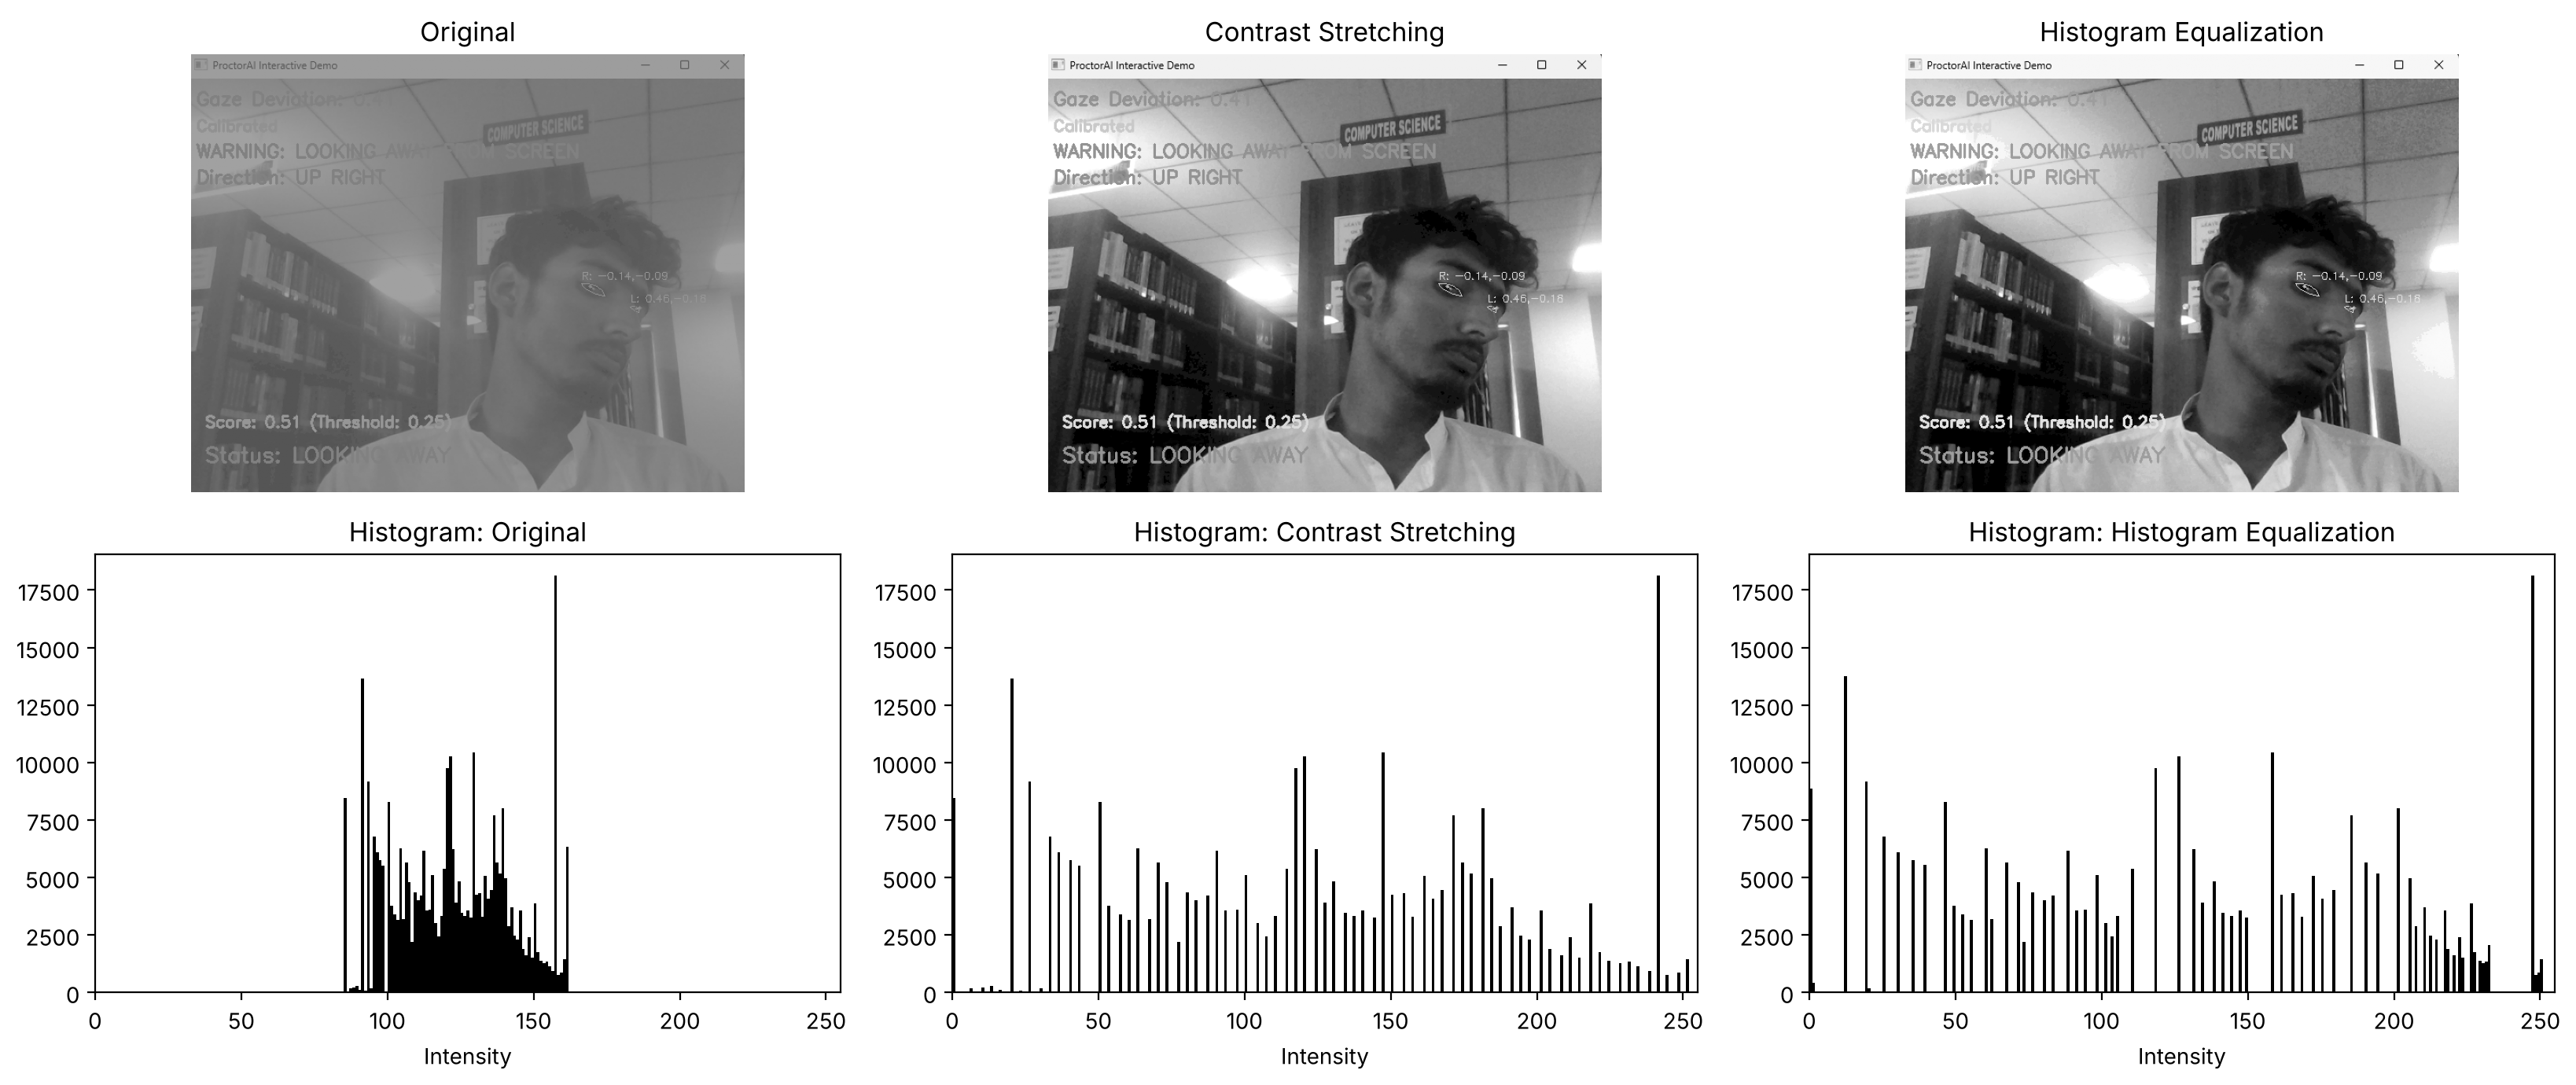

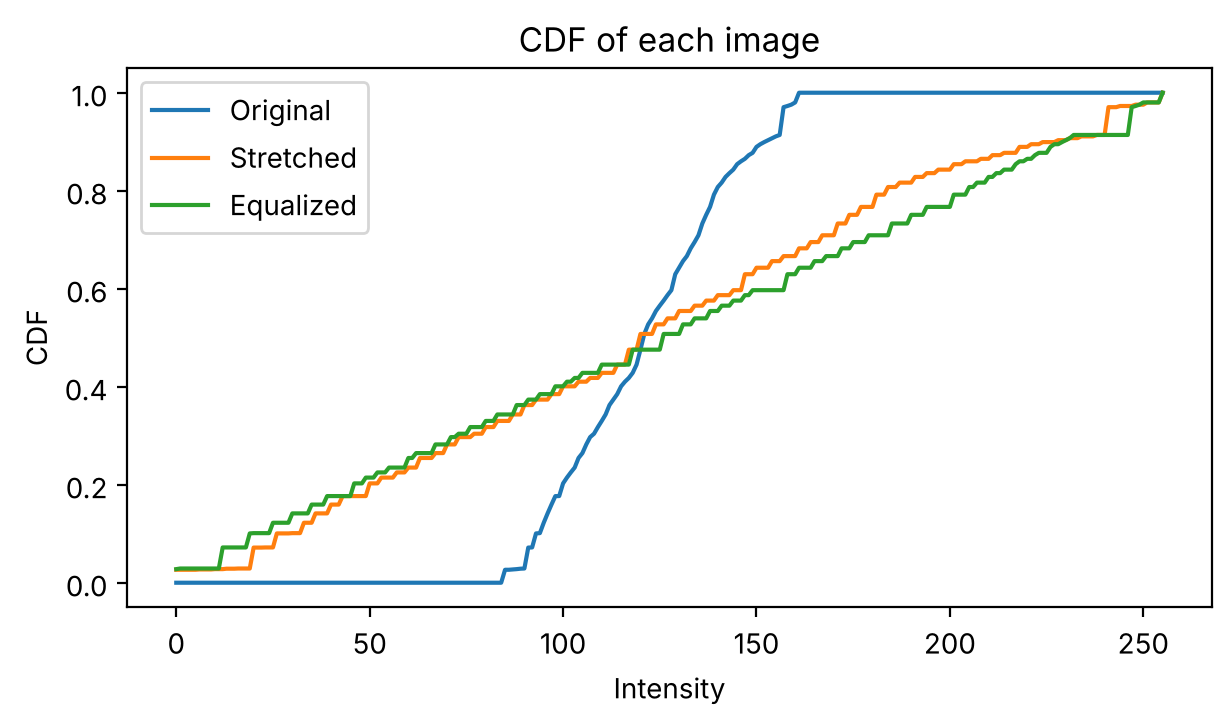

In [7]:
show_with_hist([low, stretched, equalized], ["Original", "Contrast Stretching", "Histogram Equalization"])
plt.figure(figsize=(7, 3.5))
for im, lab in [(low, "Original"), (stretched, "Stretched"), (equalized, "Equalized")]:
    c = np.cumsum(cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()) / im.size
    plt.plot(c, label=lab)
plt.title("CDF of each image"); plt.xlabel("Intensity"); plt.ylabel("CDF"); plt.legend(); plt.show()

1. **Better enhancement:** equalization shows a bit more detail, stretching looks more natural.
2. **Distributions:** stretching keeps the histogram shape, equalization flattens it (CDF close to a straight line).
3. **Linear transformation:** contrast stretching.
4. **Uses the CDF:** histogram equalization.
5. **Artificial look:** yes, the ceiling turns almost pure white and dark areas get grainy.
6. **Always better?** No. Equalization can boost noise and look unnatural; stretching is predictable and often better for a simply faded image.